Normality test results
-----------------------------------------------------------------
Linear Regression    Statistic =    7.300, p-value = 0.025995, Reject normality
SVR                  Statistic =   12.338, p-value = 0.0020929, Reject normality
Decision Tree        Statistic =    2.741, p-value = 0.25403, Fail to reject normality
Random Forest        Statistic =    5.006, p-value = 0.081849, Fail to reject normality
Neural Network       Statistic =    7.055, p-value = 0.029384, Reject normality


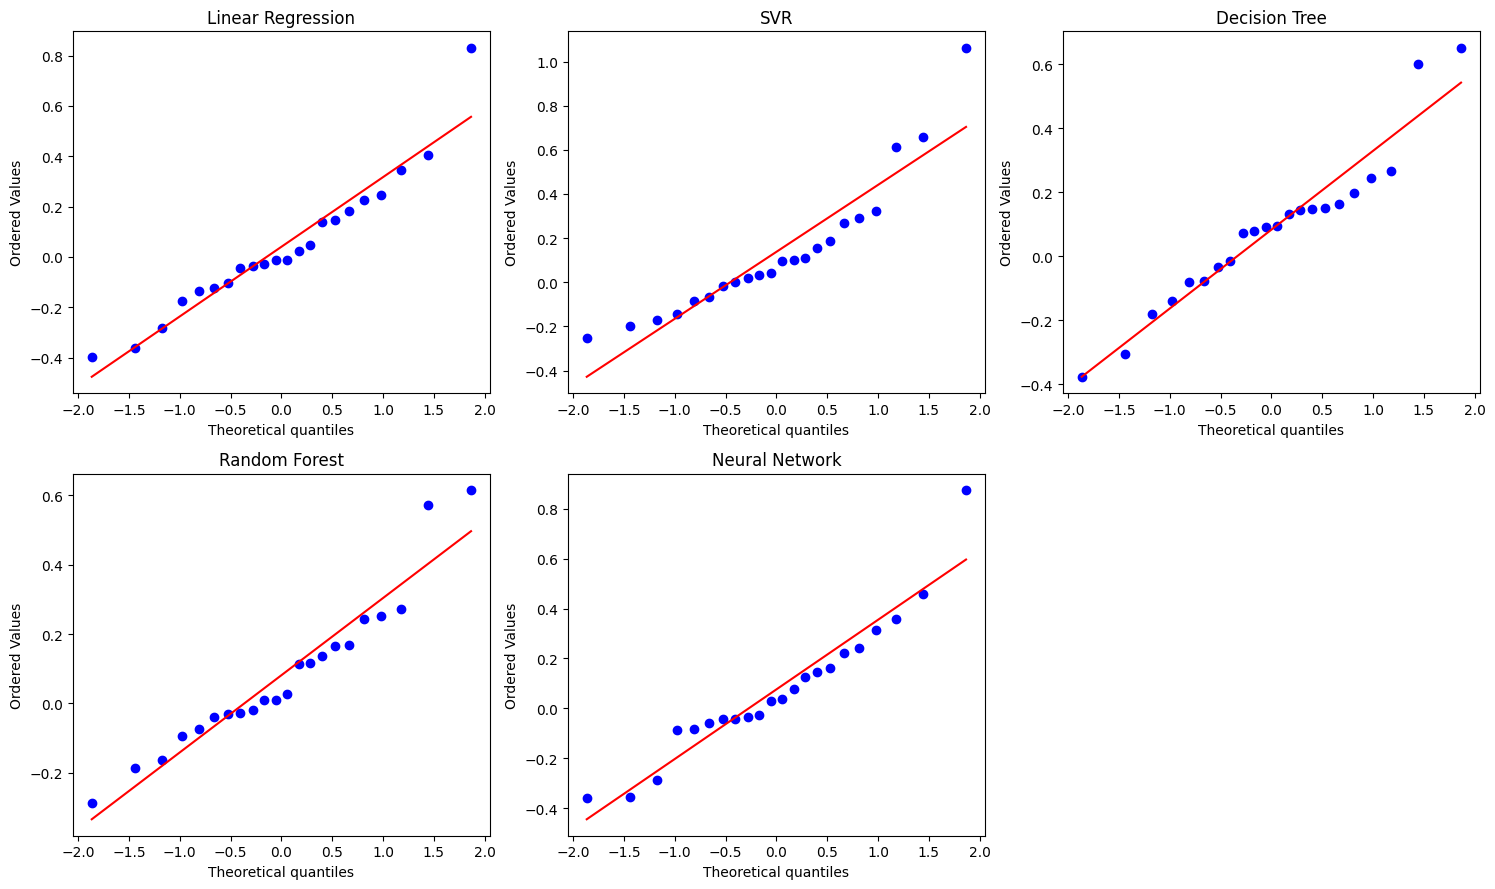

In [19]:
# Problem 4
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from scipy.stats import normaltest

# Load the dataset
df = pd.read_csv("DATA37711HW1/ALE.csv")

# Use the first four variables as predictors
X = df.iloc[:, :4]

# Predict ALE, excluding sd ale
y = df["ale"]

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Define regression models
models = {
    "Linear Regression": LinearRegression(),
    "SVR": make_pipeline(StandardScaler(), SVR()),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42
    ),
    "Neural Network": make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(50, 25),
            max_iter=2000,
            random_state=42
        )
    )
}

# Fit each model and calculate test residuals
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    residuals = y_test.to_numpy() - predictions
    results[name] = residuals

# Test normality

# Run the D'Agostino-Pearson normality test
print("Normality test results")
print("-" * 65)

for name, residuals in results.items():
    statistic, p_value = normaltest(residuals)

    conclusion = (
        "Reject normality"
        if p_value < 0.05
        else "Fail to reject normality"
    )

    print(
        f"{name:20s} "
        f"Statistic = {statistic:8.3f}, "
        f"p-value = {p_value:.5g}, "
        f"{conclusion}"
    )
# Draw qqplot

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, residuals) in enumerate(results.items()):
    stats.probplot(residuals, dist="norm", plot=axes[i])
    axes[i].set_title(name)

# Hide the unused sixth subplot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
!mkdir DATA37711HW1/

In [ ]:
# Problem 5 Classification (a)
import numpy as np
import torch
import torch.nn as nn
import importlib.util

from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

print("Features:", X.shape)
print("Labels:", y.shape)
print("Classes:", data.target_names)

# Split into training and test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize features using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

# Train baseline logistic regression
baseline = LogisticRegression(max_iter=2000)
baseline.fit(X_train, y_train)

# Predict test labels
y_pred_baseline = baseline.predict(X_test)

# Calculate accuracy
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print(f"Baseline test accuracy: {baseline_accuracy:.4f}")
print(f"Baseline test accuracy: {baseline_accuracy * 100:.2f}%")

# Convert data to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(
    y_train, dtype=torch.float32
).reshape(-1, 1)

y_test_t = torch.tensor(
    y_test, dtype=torch.float32
).reshape(-1, 1)

# Define logistic regression
class LogisticRegressionTorch(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)

    def forward(self, x):
        return self.linear(x)  # Return logits

# Initialize model
model = LogisticRegressionTorch(X_train.shape[1])

# Binary cross-entropy with logits
criterion = nn.BCEWithLogitsLoss()

# Stochastic gradient descent optimizer
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

# Mini-batch training
dataset = TensorDataset(X_train_t, y_train_t)
loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

epochs = 200

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for xb, yb in loader:
        # Forward pass
        logits = model(xb)
        loss = criterion(logits, yb)

        # Backpropagation and SGD update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    if (epoch + 1) % 20 == 0:
        avg_loss = total_loss / len(dataset)
        print(
            f"Epoch {epoch + 1:3d}, "
            f"Loss: {avg_loss:.4f}"
        )
# Evaluate the model AFTER training finishes
model.eval()

with torch.no_grad():
    test_logits = model(X_test_t)
    probabilities = torch.sigmoid(test_logits)
    y_pred_torch = (probabilities >= 0.5).int().numpy().ravel()

torch_accuracy = accuracy_score(y_test, y_pred_torch)

print(f"PyTorch test accuracy: {torch_accuracy:.4f}")
print(f"PyTorch test accuracy: {torch_accuracy * 100:.2f}%")

print("\nTest Accuracy Comparison")
print("------------------------")
print(f"Scikit-learn: {baseline_accuracy:.4f}")
print(f"PyTorch SGD:  {torch_accuracy:.4f}")
print(f"Difference:   {torch_accuracy - baseline_accuracy:+.4f}")

Features: (569, 30)
Labels: (569,)
Classes: ['malignant' 'benign']
Training samples: 455
Test samples: 114
Baseline test accuracy: 0.9825
Baseline test accuracy: 98.25%
Epoch  20, Loss: 0.1575
Epoch  40, Loss: 0.1200
Epoch  60, Loss: 0.1042
Epoch  80, Loss: 0.0946
Epoch 100, Loss: 0.0882
Epoch 120, Loss: 0.0835
Epoch 140, Loss: 0.0799
Epoch 160, Loss: 0.0771
Epoch 180, Loss: 0.0748
Epoch 200, Loss: 0.0728
PyTorch test accuracy: 0.9737
PyTorch test accuracy: 97.37%

Test Accuracy Comparison
------------------------
Scikit-learn: 0.9825
PyTorch SGD:  0.9737
Difference:   -0.0088


In [ ]:
# Problem 5 Classification (b)
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score

# Define probit regression
class ProbitRegression(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)
        self.normal = torch.distributions.Normal(0.0, 1.0)

    def forward(self, x):
        z = self.linear(x)
        probabilities = self.normal.cdf(z)
        return torch.clamp(probabilities, 1e-7, 1 - 1e-7)

# Initialize model
torch.manual_seed(42)
probit_model = ProbitRegression(X_train_t.shape[1])

# Binary cross-entropy loss
criterion = nn.BCELoss()

# SGD optimizer
optimizer = torch.optim.SGD(
    probit_model.parameters(),
    lr=0.01
)

# Training data loader
dataset = TensorDataset(X_train_t, y_train_t)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

# Train model
epochs = 200

for epoch in range(epochs):
    probit_model.train()
    total_loss = 0.0

    for xb, yb in loader:
        probabilities = probit_model(xb)
        loss = criterion(probabilities, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Loss = {total_loss / len(dataset):.4f}"
        )
# Evaluate test accuracy
probit_model.eval()

with torch.no_grad():
    probit_probabilities = probit_model(X_test_t)
    probit_predictions = (
        probit_probabilities >= 0.5
    ).int().numpy().ravel()

probit_accuracy = accuracy_score(y_test, probit_predictions)

print(f"Probit test accuracy: {probit_accuracy:.4f}")
print(f"Probit test accuracy: {probit_accuracy * 100:.2f}%")

# Compare probit regression with baseline
print("Test accuracy comparison")
print("-------------------------")
print(f"Scikit-learn logistic regression: {baseline_accuracy:.4f}")
print(f"PyTorch probit regression:        {probit_accuracy:.4f}")
print(f"Difference:                       {probit_accuracy - baseline_accuracy:+.4f}")



Epoch 20: Loss = 0.1038
Epoch 40: Loss = 0.0839
Epoch 60: Loss = 0.0757
Epoch 80: Loss = 0.0705
Epoch 100: Loss = 0.0671
Epoch 120: Loss = 0.0647
Epoch 140: Loss = 0.0627
Epoch 160: Loss = 0.0613
Epoch 180: Loss = 0.0600
Epoch 200: Loss = 0.0588
Probit test accuracy: 0.9737
Probit test accuracy: 97.37%
Test accuracy comparison
-------------------------
Scikit-learn logistic regression: 0.9825
PyTorch probit regression:        0.9737
Difference:                       -0.0088


In [14]:
# Problem 5 - Regression: Baseline
# Dataset: Average Localization Error (ALE)
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Load ALE dataset
ale_df = pd.read_csv("DATA37711HW1/ALE.csv")

# Predictors and target
X_ale = ale_df.iloc[:, :4].to_numpy(dtype=np.float32)
y_ale = ale_df["ale"].to_numpy(dtype=np.float32)

# Split into 80% training and 20% testing
X_ale_train_raw, X_ale_test_raw, y_ale_train, y_ale_test = (
    train_test_split(
        X_ale,
        y_ale,
        test_size=0.20,
        random_state=42
    )
)

# Standardize features using training data only
scaler_ale = StandardScaler()
X_ale_train = scaler_ale.fit_transform(
    X_ale_train_raw
).astype(np.float32)

X_ale_test = scaler_ale.transform(
    X_ale_test_raw
).astype(np.float32)

# Scikit-learn linear regression baseline
baseline_ale = LinearRegression()
baseline_ale.fit(X_ale_train, y_ale_train)

y_ale_pred_baseline = baseline_ale.predict(X_ale_test)

baseline_mae = mean_absolute_error(
    y_ale_test, y_ale_pred_baseline
)

print("ALE Linear Regression Baseline")
print(f"Test MAE: {baseline_mae:.6f}")

# Prepare tensors for the PyTorch models
X_ale_train_t = torch.tensor(
    X_ale_train, dtype=torch.float32
)
X_ale_test_t = torch.tensor(
    X_ale_test, dtype=torch.float32
)
y_ale_train_t = torch.tensor(
    y_ale_train.reshape(-1, 1), dtype=torch.float32
)


ALE Linear Regression Baseline
Test MAE: 0.195393


In [15]:
# Problem 5 - Regression (a)
# PyTorch Linear Regression with MSE Loss

torch.manual_seed(42)

model_mse = nn.Linear(X_ale_train.shape[1], 1)

criterion_mse = nn.MSELoss()
optimizer_mse = torch.optim.SGD(
    model_mse.parameters(), lr=0.01
)

epochs = 1000

for epoch in range(epochs):
    model_mse.train()

    predictions = model_mse(X_ale_train_t)
    loss = criterion_mse(predictions, y_ale_train_t)

    optimizer_mse.zero_grad()
    loss.backward()
    optimizer_mse.step()

# Predict on test data
model_mse.eval()
with torch.no_grad():
    y_ale_pred_mse = (
        model_mse(X_ale_test_t).numpy().ravel()
    )

# Evaluate test MAE
mae_mse = mean_absolute_error(
    y_ale_test, y_ale_pred_mse
)

print("PyTorch Linear Regression (MSE Loss)")
print(f"Test MAE: {mae_mse:.6f}")

print("\nComparison with baseline:")
print(f"Scikit-learn baseline MAE: {baseline_mae:.6f}")
print(f"PyTorch MSE model MAE:     {mae_mse:.6f}")


PyTorch Linear Regression (MSE Loss)
Test MAE: 0.195392

Comparison with baseline:
Scikit-learn baseline MAE: 0.195393
PyTorch MSE model MAE:     0.195392


In [16]:
# Problem 5 - Regression (b)
# PyTorch Linear Regression with Student-t Loss

torch.manual_seed(42)

model_student_t = nn.Linear(X_ale_train.shape[1], 1)

nu = 5
student_t = torch.distributions.StudentT(df=nu)

optimizer_t = torch.optim.SGD(
    model_student_t.parameters(), lr=0.01
)

epochs = 1000

for epoch in range(epochs):
    model_student_t.train()

    predictions = model_student_t(X_ale_train_t)
    residuals = y_ale_train_t - predictions

    # Negative log-likelihood of Student-t residuals
    loss = -student_t.log_prob(residuals).mean()

    optimizer_t.zero_grad()
    loss.backward()
    optimizer_t.step()

# Predict on test data
model_student_t.eval()
with torch.no_grad():
    y_ale_pred_t = (
        model_student_t(X_ale_test_t).numpy().ravel()
    )

# Evaluate test MAE
mae_student_t = mean_absolute_error(
    y_ale_test, y_ale_pred_t
)

print("PyTorch Linear Regression (Student-t Loss, nu=5)")
print(f"Test MAE: {mae_student_t:.6f}")

print("\nComparison with baseline:")
print(f"Scikit-learn baseline MAE: {baseline_mae:.6f}")
print(f"PyTorch MSE model MAE:     {mae_mse:.6f}")
print(f"PyTorch Student-t MAE:     {mae_student_t:.6f}")


PyTorch Linear Regression (Student-t Loss, nu=5)
Test MAE: 0.194069

Comparison with baseline:
Scikit-learn baseline MAE: 0.195393
PyTorch MSE model MAE:     0.195392
PyTorch Student-t MAE:     0.194069
